# Pipeline klasyfikacji chorób serca

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

df = pd.read_csv("heart_disease_cleaned.csv")
df["target"] = (df["num"] > 0).astype(int)

print(f"Wymiary danych: {df.shape}")
print("Liczebność klas celu:")
print(df["target"].value_counts().sort_index())
print(f"Brakujące wartości: {df.isna().sum().sum()}")

Wymiary danych: (919, 17)
Liczebność klas celu:
target
0    411
1    508
Name: count, dtype: int64
Brakujące wartości: 0


## Eksploracyjna analiza danych

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,919.0,NaN,NaN,NaN,53.509249,9.429689,28.0,47.0,54.0,60.0,77.0
sex,919,2,Male,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,919,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,919.0,NaN,NaN,NaN,132.704853,18.070335,80.0,120.0,130.0,141.21,200.0
chol,919.0,NaN,NaN,NaN,200.791393,109.213597,0.0,178.5,224.0,268.0,603.0
fbs,919,2,False,781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,919,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,919.0,NaN,NaN,NaN,136.815734,25.37126,60.0,120.0,138.0,156.0,202.0
exang,919,2,False,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldpeak,919.0,NaN,NaN,NaN,0.973408,1.12049,-2.6,0.0,0.8,1.9,6.2


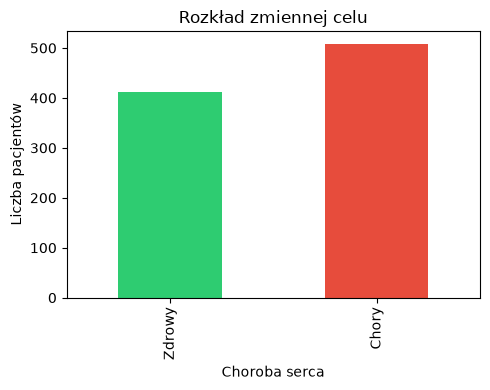

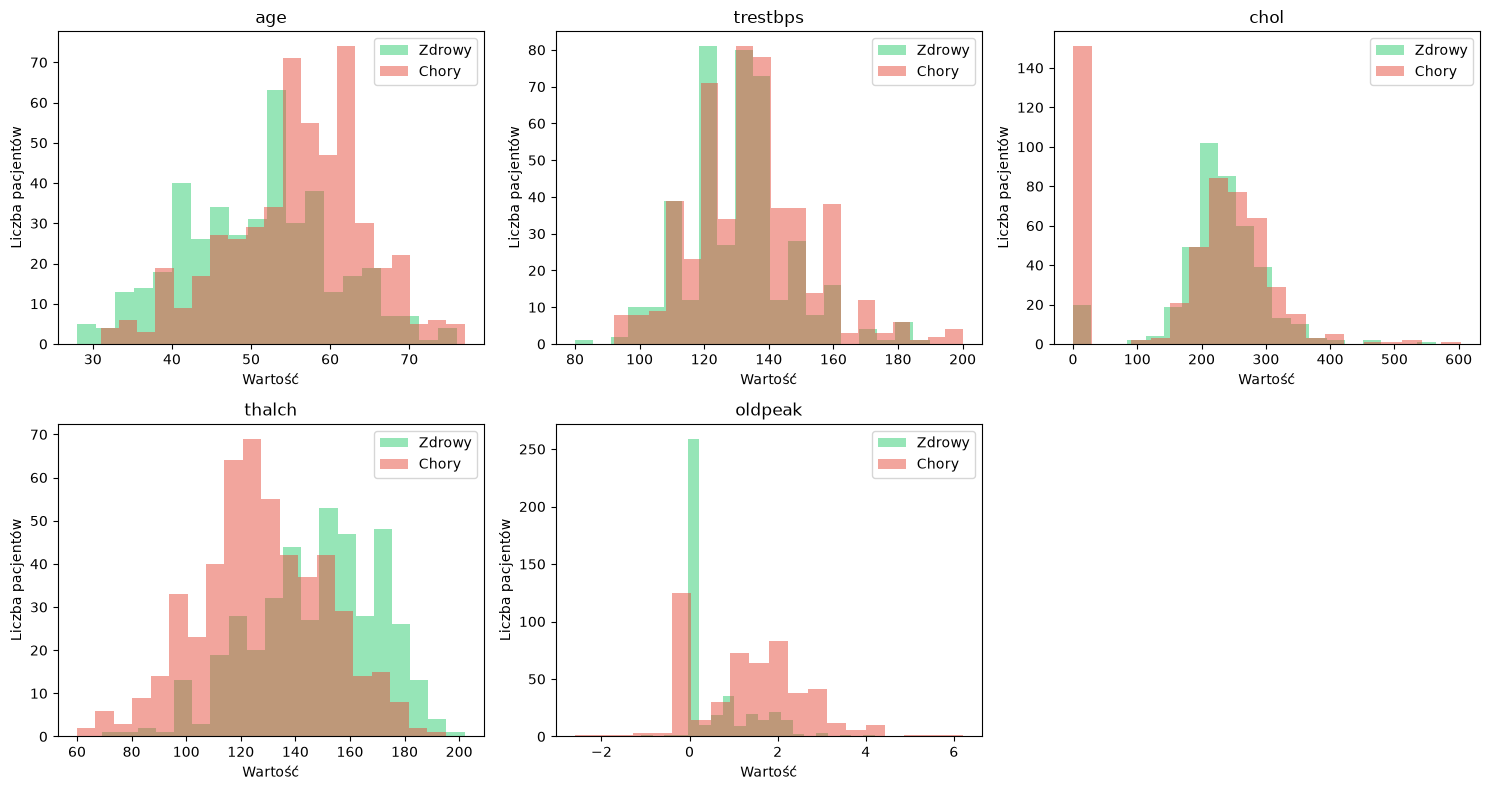

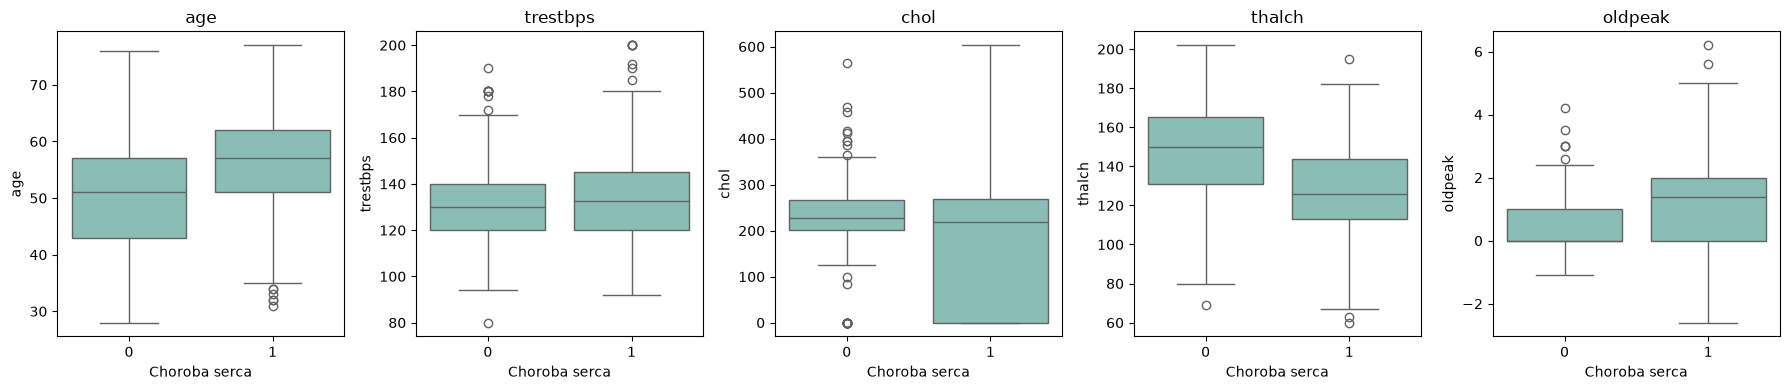

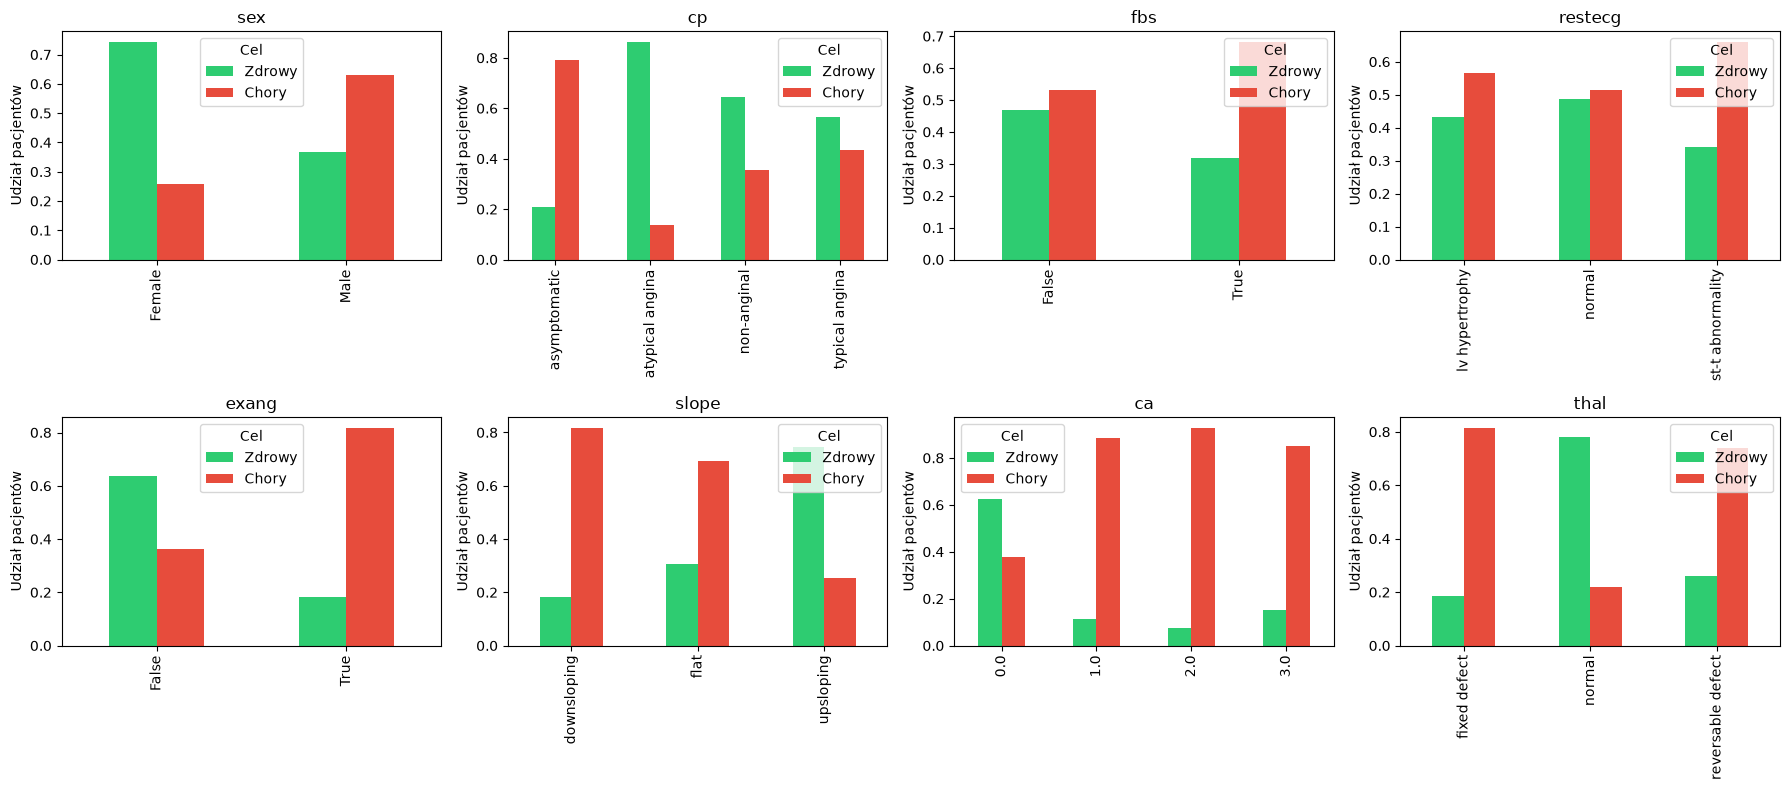

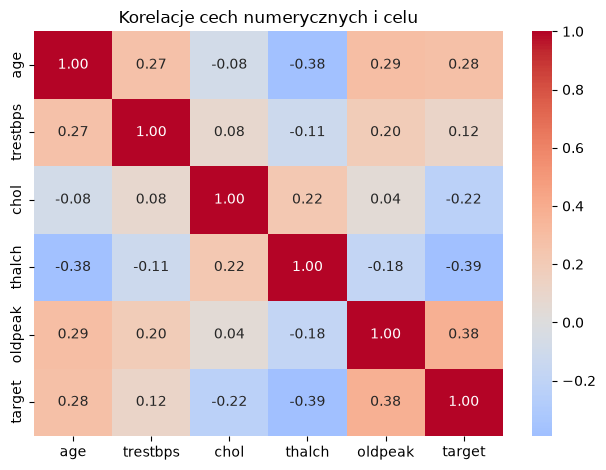

In [ ]:
numeric_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
print(df.drop(columns=["id", "dataset"]).describe(include="all").T)

target_counts = df["target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
target_counts.plot(kind="bar", ax=ax, color=["#2ecc71", "#e74c3c"])
ax.set(title="Rozkład zmiennej celu", xlabel="Choroba serca", ylabel="Liczba pacjentów", xticks=[0, 1], xticklabels=["Zdrowy", "Chory"])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    for target_value, label, color in [(0, "Zdrowy", "#2ecc71"), (1, "Chory", "#e74c3c")]:
        df.loc[df["target"] == target_value, col].plot.hist(bins=20, alpha=0.5, label=label, color=color, ax=ax)
    ax.set(title=col, xlabel="Wartość", ylabel="Liczba pacjentów")
    ax.legend()
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="target", y=col, ax=ax, color="#83c5be")
    ax.set(title=col, xlabel="Choroba serca", ylabel=col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, categorical_cols):
    pd.crosstab(df[col], df["target"], normalize="index").plot(kind="bar", ax=ax, color=["#2ecc71", "#e74c3c"])
    ax.set(title=col, xlabel="", ylabel="Udział pacjentów")
    ax.legend(["Zdrowy", "Chory"], title="Cel")
plt.tight_layout()
plt.show()

correlation_cols = numeric_cols + ["target"]
correlation = df[correlation_cols].corr()["target"].drop("target")
sns.heatmap(df[correlation_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelacje cech numerycznych i celu")
plt.tight_layout()
plt.show()

median_by_class = df.groupby("target")[numeric_cols].median()
categorical_spread = pd.Series({
    col: pd.crosstab(df[col], df["target"], normalize="index")[1].max()
    - pd.crosstab(df[col], df["target"], normalize="index")[1].min()
    for col in categorical_cols
})
strongest_correlation = correlation.abs().idxmax()
widest_categorical_gap = categorical_spread.idxmax()

## Przygotowanie cech i podział danych

In [ ]:
df_model = df.copy()
thal_map = {"normal": 0, "reversable defect": 1, "fixed defect": 2}
df_model["chol_age"] = df_model["chol"] / df_model["age"]

X = df_model.drop(columns=["id", "dataset", "num", "target"])
y = df_model["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

print(pd.Series({
    "Train": len(X_train),
    "Walidacja": len(X_valid),
    "Test": len(X_test),
}, name="Liczba obserwacji"))

Train        551
Walidacja    184
Test         184
Name: Liczba obserwacji, dtype: int64

## Preprocessing i trenowanie modeli

In [ ]:
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

models = {
    "Regresja logistyczna": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {
            "classifier__C": [0.01, 0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Drzewo decyzyjne": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "classifier__max_depth": [None, 3, 5, 8],
            "classifier__min_samples_leaf": [1, 3, 5],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 5, 10],
            "classifier__min_samples_leaf": [1, 3],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [50, 100, 150],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__max_depth": [1, 2, 3],
            "classifier__min_samples_leaf": [1, 3],
        },
    ),
}

searches = {}
model_scores = []

for name, (classifier, parameter_options) in models.items():
    pipeline = Pipeline(
        steps=[("preprocessing", preprocessor), ("classifier", classifier)]
    )
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_options,
        n_iter=8,
        scoring="recall",
        cv=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search

    valid_probabilities = search.best_estimator_.predict_proba(X_valid)[:, 1]
    valid_predictions = (valid_probabilities >= 0.5).astype(int)
    model_scores.append(
        {
            "Model": name,
            "Recall CV": search.best_score_,
            "Accuracy": accuracy_score(y_valid, valid_predictions),
            "Recall walidacja": recall_score(y_valid, valid_predictions),
            "Precision": precision_score(y_valid, valid_predictions, zero_division=0),
            "F1": f1_score(y_valid, valid_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_valid, valid_probabilities),
            "PR-AUC": average_precision_score(y_valid, valid_probabilities),
        }
    )

model_results = pd.DataFrame(model_scores).sort_values(
    ["Recall CV", "F1"], ascending=False
).reset_index(drop=True)
print(model_results.round(3))

,Model,Recall CV,Accuracy,Recall walidacja,Precision,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.875,0.870,0.861,0.897,0.879,0.931,0.943
1,Regresja logistyczna,0.875,0.848,0.861,0.861,0.861,0.890,0.901
2,Random Forest,0.872,0.875,0.871,0.898,0.884,0.935,0.946
3,Drzewo decyzyjne,0.807,0.783,0.802,0.802,0.802,0.859,0.855


## Porównanie na zbiorze walidacyjnym

Regresja logistyczna: {'classifier__class_weight': None, 'classifier__C': 0.01}
Drzewo decyzyjne: {'classifier__min_samples_leaf': 3, 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}
Random Forest: {'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 3, 'classifier__max_depth': 10, 'classifier__class_weight': None}
Gradient Boosting: {'classifier__n_estimators': 50, 'classifier__min_samples_leaf': 3, 'classifier__max_depth': 1, 'classifier__learning_rate': 0.1}


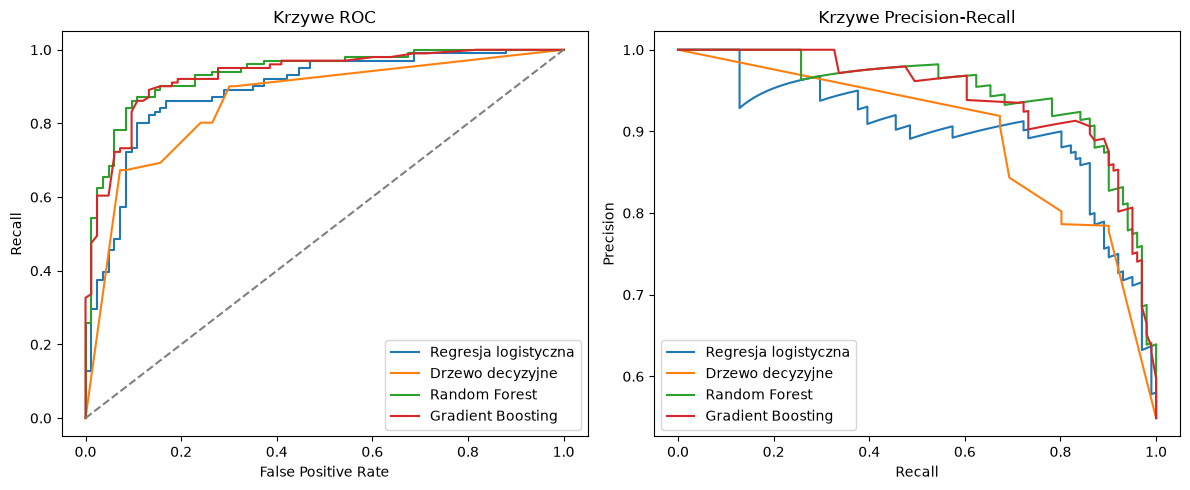

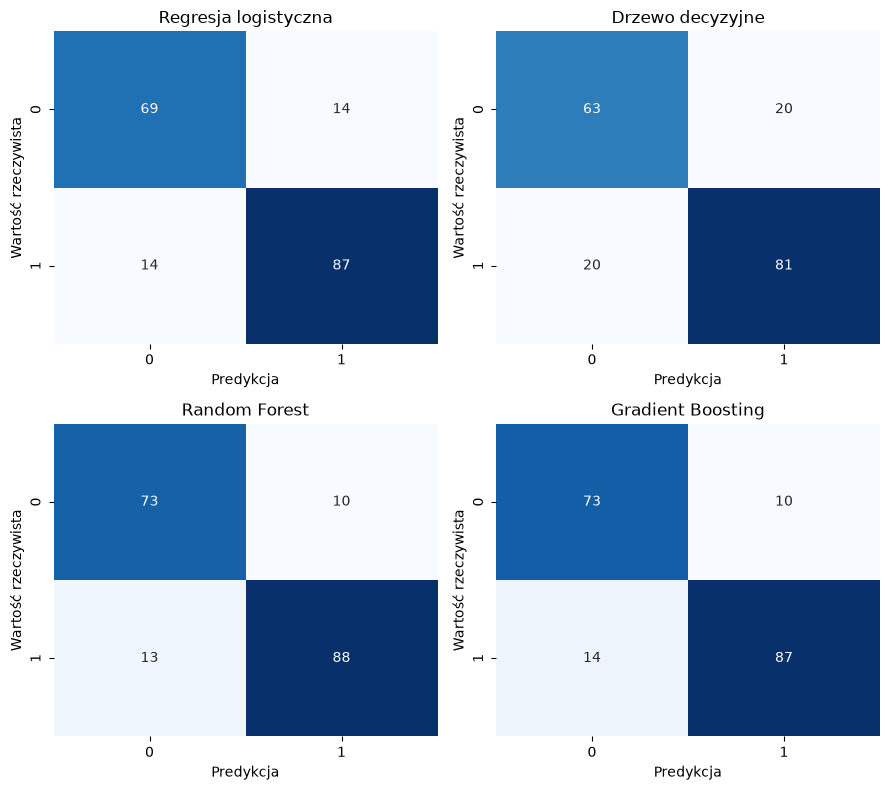

In [65]:
for name, search in searches.items():
    print(f"{name}: {search.best_params_}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(X_valid)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_valid, probabilities)
    precision, recall, _ = precision_recall_curve(y_valid, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate, label=name)
    axes[1].plot(recall, precision, label=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="Krzywe ROC", xlabel="False Positive Rate", ylabel="Recall")
axes[1].set(title="Krzywe Precision-Recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (name, search) in zip(axes.flat, searches.items()):
    predictions = search.best_estimator_.predict(X_valid)
    sns.heatmap(
        confusion_matrix(y_valid, predictions, labels=[0, 1]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
    )
    ax.set(title=name, xlabel="Predykcja", ylabel="Wartość rzeczywista")
plt.tight_layout()
plt.show()